In [5]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [6]:
import os

print(os.listdir('/content/drive/MyDrive'))

['cse', 'Classroom', 'RS', 'Google Photos', 'cse110_8v10', 'Lab 1 v10', 'New folder (1)', 'cse 111 lab', 'matlab.rar', 'matlab', 'LAB06', 'cse111lab08', 'mystring', 'MyMatrix', 'Summer 2019', 'Sparna.gdoc', 'PB__8246-aa-a.jpg', '1-COver-.jpg', 'blog-n-designer--768x512.jpg', 'do it on matlab.txt', 'Day 1', 'Day 2', 'Task_04.m', 'Ass.docx', 'lab_09', 'ch07_Transmission_Media.zslides', '03-Ch3_Signals.zslides', 'tools', 'Book (1)', 'NaylaPre!!!!!!!!!!!!!!!', 'Lectures (1)', 'Final Qus', '421_Grades_Fall19_Sec3.xlsx', 'Junks', 'Fall2019', 'Lab01', 'Software', 'Resume.gdoc', 'Lectures', 'Book', 'old', 'Natural Language Processing (NLP) v4.docx', 'ip.txt', 'piazza.txt', 'FBA Lab', 'Lab02 (1)', 'practice', 'pic', 'EER diagram.docx.pdf', 'Untitled document (21).gdoc', 'diagram.JPG', 'mid.docx', 'stat201', 'Lab02', 'New folder', 'March32020', 'Lab03', 'PROJECT IDEA SUBMISSION', 'Introductory Slides', 'Lab04', 'Intro to ML.txt', 'sales.csv', 'StockPriceData_simple_linear_regression.csv', 'STA20

In [7]:
# ================================
# IMPORT LIBRARIES
# ================================

import os
import zipfile
import cv2
import random
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from collections import Counter

warnings.filterwarnings('ignore')

In [8]:
# ================================
# ZIP FILE PATH
# ================================

zip_path = "/content/drive/MyDrive/Nishat_Nayla_MSC_Thesis/Datasets/Alzheimer/archive.zip"

In [9]:
# ================================
# EXTRACT DATASET
# ================================

extract_path = "/content/alzheimer_dataset"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset Extracted Successfully!")

Dataset Extracted Successfully!


In [10]:
# ================================
# FINAL DATASET PATH
# ================================

dataset_path = "/content/alzheimer_dataset/AugmentedAlzheimerDataset"

classes = os.listdir(dataset_path)

print("Classes Found:")
print(classes)

Classes Found:
['VeryMildDemented', 'ModerateDemented', 'MildDemented', 'NonDemented']


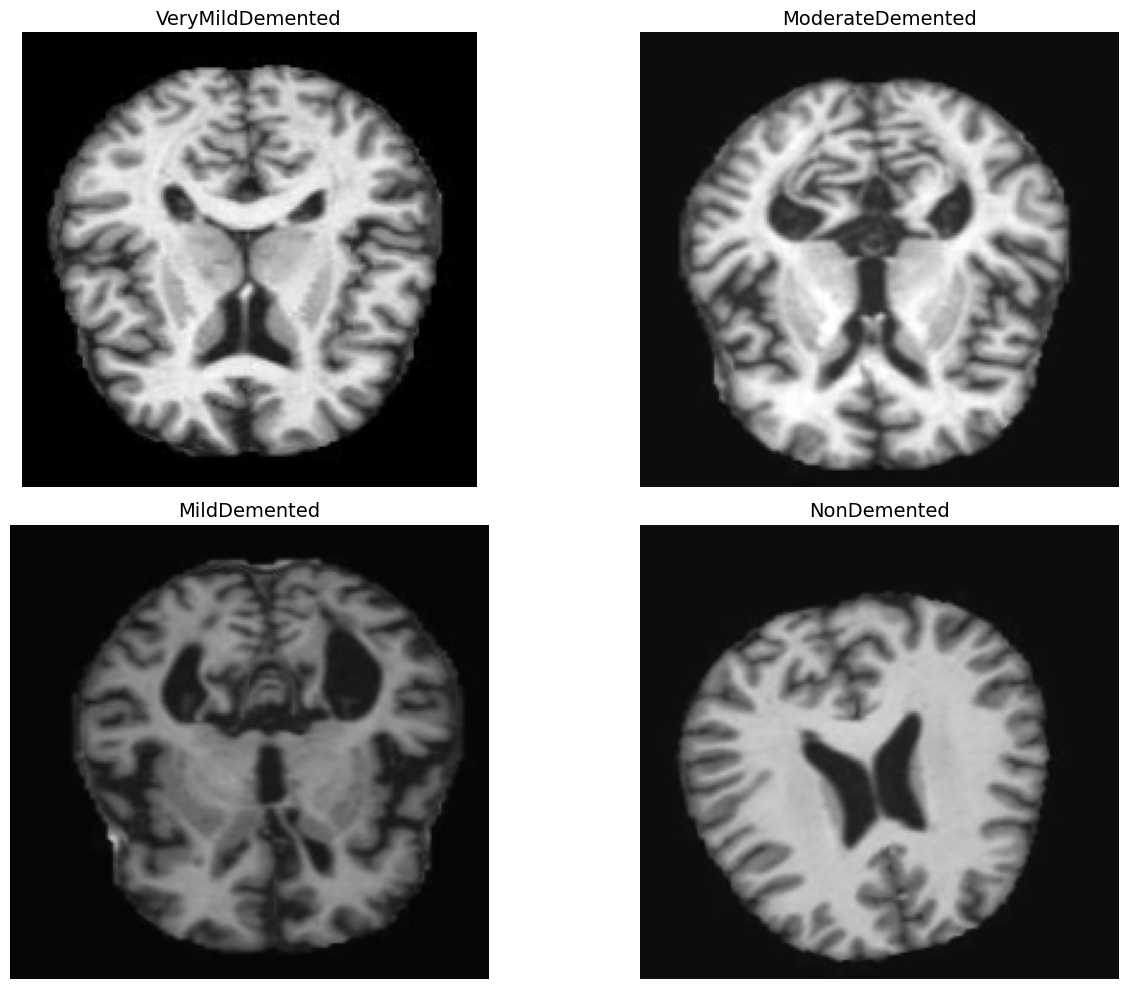

In [11]:
# showing one real MRI image from each category

plt.figure(figsize=(14,10))

for i, cls in enumerate(classes):

    class_path = os.path.join(dataset_path, cls)

    img_name = os.listdir(class_path)[0]

    img_path = os.path.join(class_path, img_name)

    img = cv2.imread(img_path)

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(2,2,i+1)

    plt.imshow(img)

    plt.title(cls, fontsize=14)

    plt.axis('off')

plt.tight_layout()

plt.show()

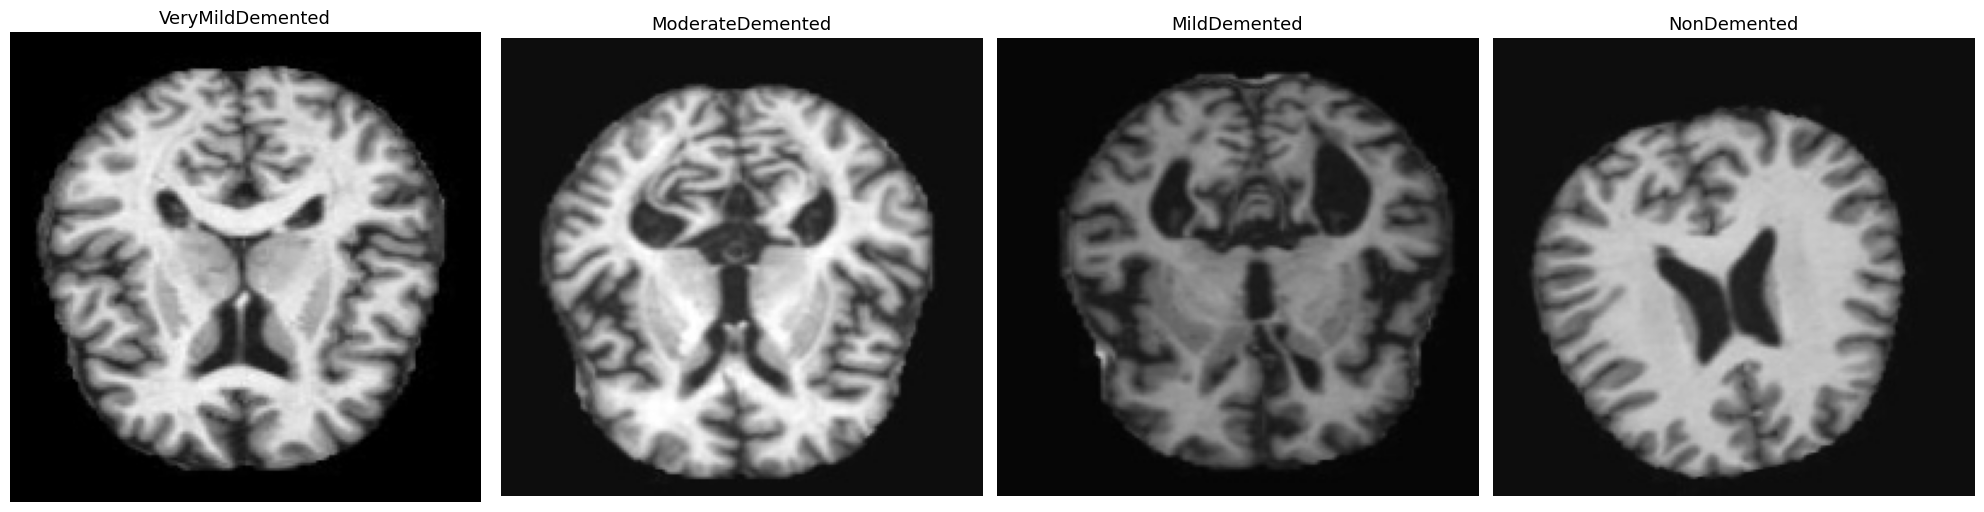

In [12]:
# showing one MRI image from each category side by side

plt.figure(figsize=(20,5))

for i, cls in enumerate(classes):

    class_path = os.path.join(dataset_path, cls)

    img_name = os.listdir(class_path)[0]

    img_path = os.path.join(class_path, img_name)

    img = cv2.imread(img_path)

    img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

    plt.subplot(1,4,i+1)

    plt.imshow(img)

    plt.title(cls, fontsize=13)

    plt.axis('off')

plt.tight_layout()

plt.show()

In [13]:
# counting total images in each category

class_counts = {}

for cls in classes:

    class_path = os.path.join(dataset_path, cls)

    total_images = len(os.listdir(class_path))

    class_counts[cls] = total_images

df_counts = pd.DataFrame({
    'Class': class_counts.keys(),
    'Images': class_counts.values()
})

df_counts

,Class,Images
0,VeryMildDemented,8960
1,ModerateDemented,6464
2,MildDemented,8960
3,NonDemented,9600


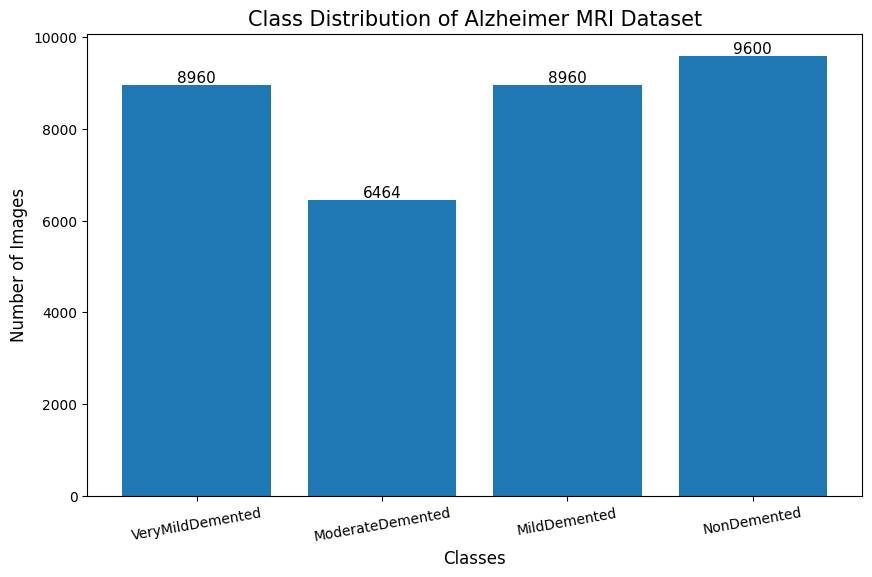

In [14]:
# bar plot of class distribution

plt.figure(figsize=(10,6))

bars = plt.bar(
    df_counts['Class'],
    df_counts['Images']
)

plt.title('Class Distribution of Alzheimer MRI Dataset', fontsize=15)

plt.xlabel('Classes', fontsize=12)

plt.ylabel('Number of Images', fontsize=12)

plt.xticks(rotation=10)

for bar in bars:

    height = bar.get_height()

    plt.text(
        bar.get_x() + bar.get_width()/2,
        height + 50,
        str(height),
        ha='center',
        fontsize=11
    )

plt.show()

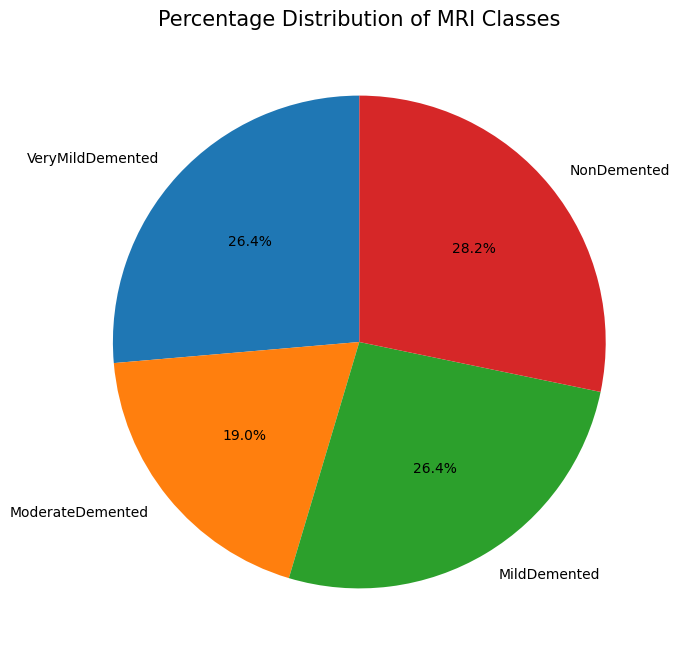

In [15]:
# pie chart of dataset distribution

plt.figure(figsize=(8,8))

plt.pie(
    df_counts['Images'],
    labels=df_counts['Class'],
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Percentage Distribution of MRI Classes', fontsize=15)

plt.show()

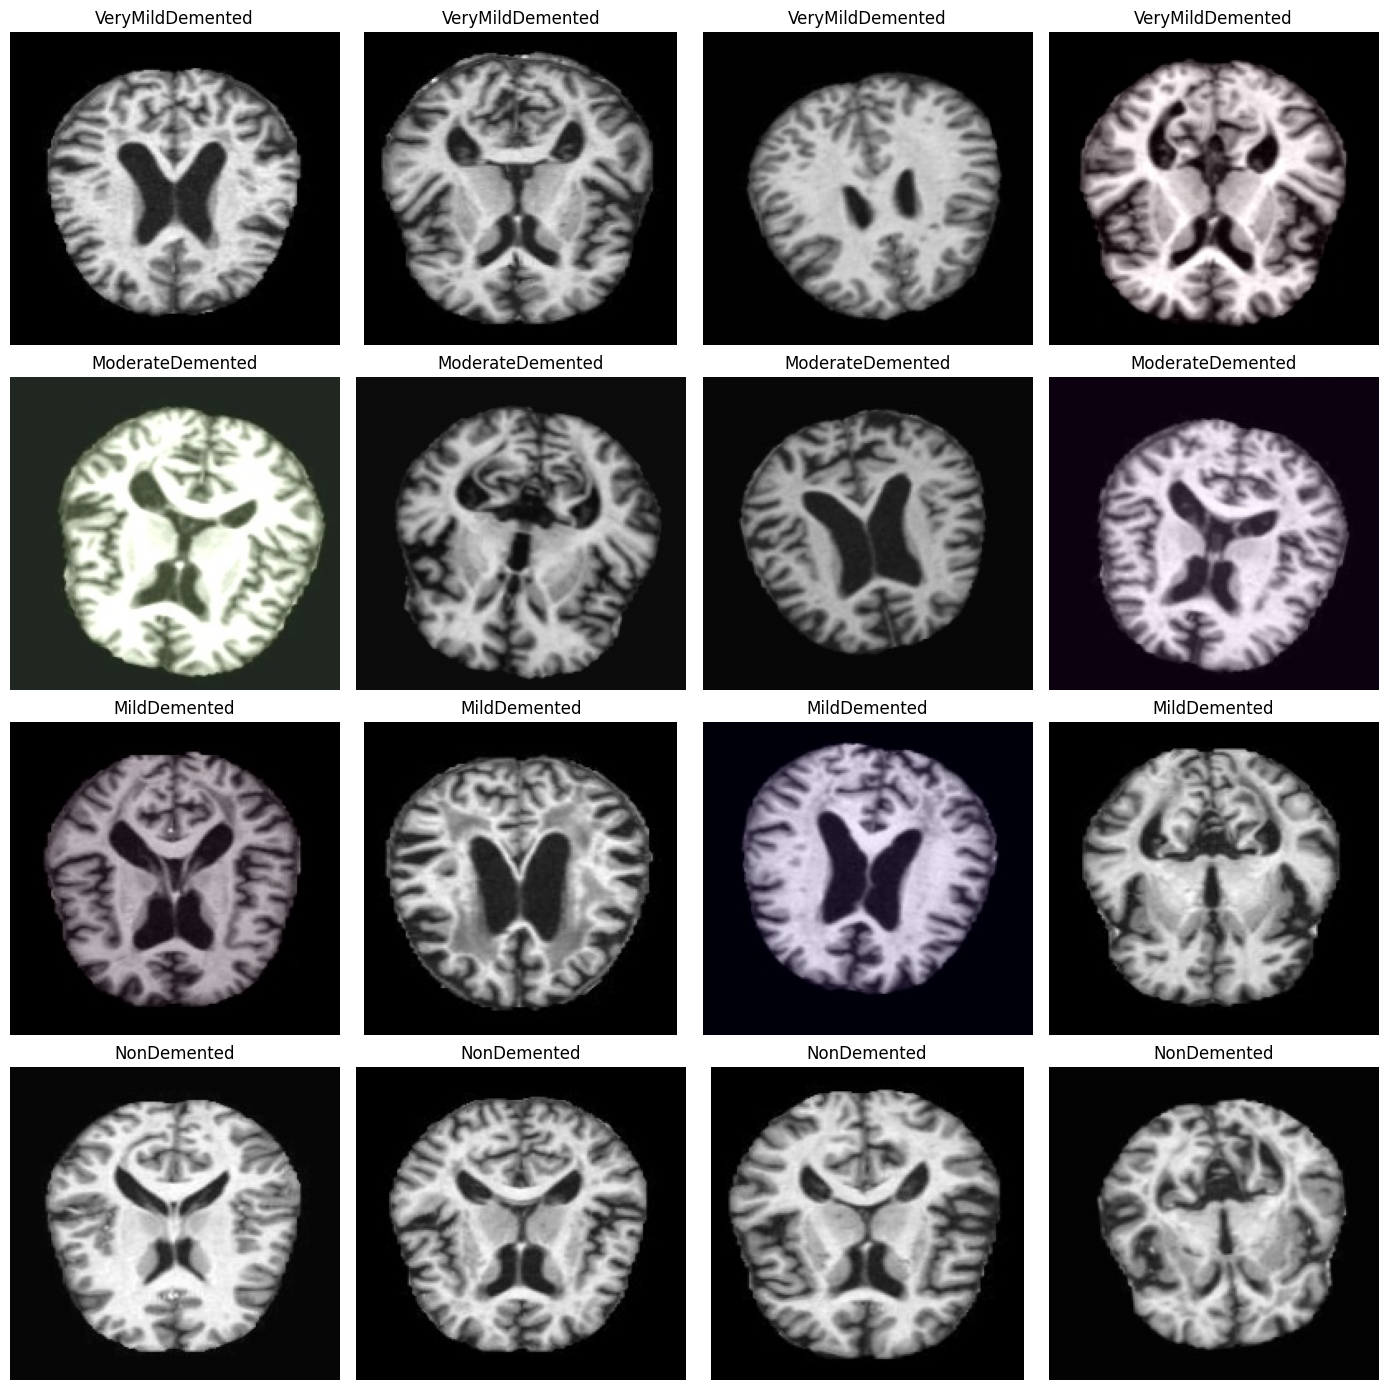

In [16]:
# displaying multiple random MRI images from each category

fig, axes = plt.subplots(4,4, figsize=(14,14))

for i, cls in enumerate(classes):

    class_path = os.path.join(dataset_path, cls)

    images = os.listdir(class_path)

    random_images = random.sample(images, 4)

    for j, img_name in enumerate(random_images):

        img_path = os.path.join(class_path, img_name)

        img = cv2.imread(img_path)

        img = cv2.cvtColor(img, cv2.COLOR_BGR2RGB)

        axes[i,j].imshow(img)

        axes[i,j].set_title(cls)

        axes[i,j].axis('off')

plt.tight_layout()

plt.show()

In [17]:
# checking image dimensions

widths = []
heights = []

for cls in classes:

    class_path = os.path.join(dataset_path, cls)

    for img_name in os.listdir(class_path):

        img_path = os.path.join(class_path, img_name)

        img = Image.open(img_path)

        width, height = img.size

        widths.append(width)

        heights.append(height)

print("Unique Widths :", set(widths))

print("Unique Heights:", set(heights))

Unique Widths : {200, 180}
Unique Heights: {180, 190}


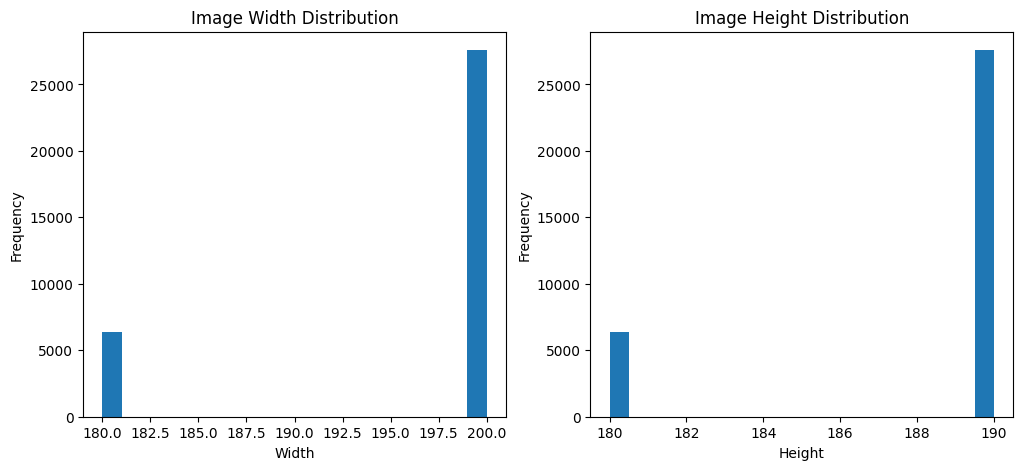

In [18]:
# histogram of image widths and heights

plt.figure(figsize=(12,5))

plt.subplot(1,2,1)

plt.hist(widths, bins=20)

plt.title('Image Width Distribution')

plt.xlabel('Width')

plt.ylabel('Frequency')

plt.subplot(1,2,2)

plt.hist(heights, bins=20)

plt.title('Image Height Distribution')

plt.xlabel('Height')

plt.ylabel('Frequency')

plt.show()

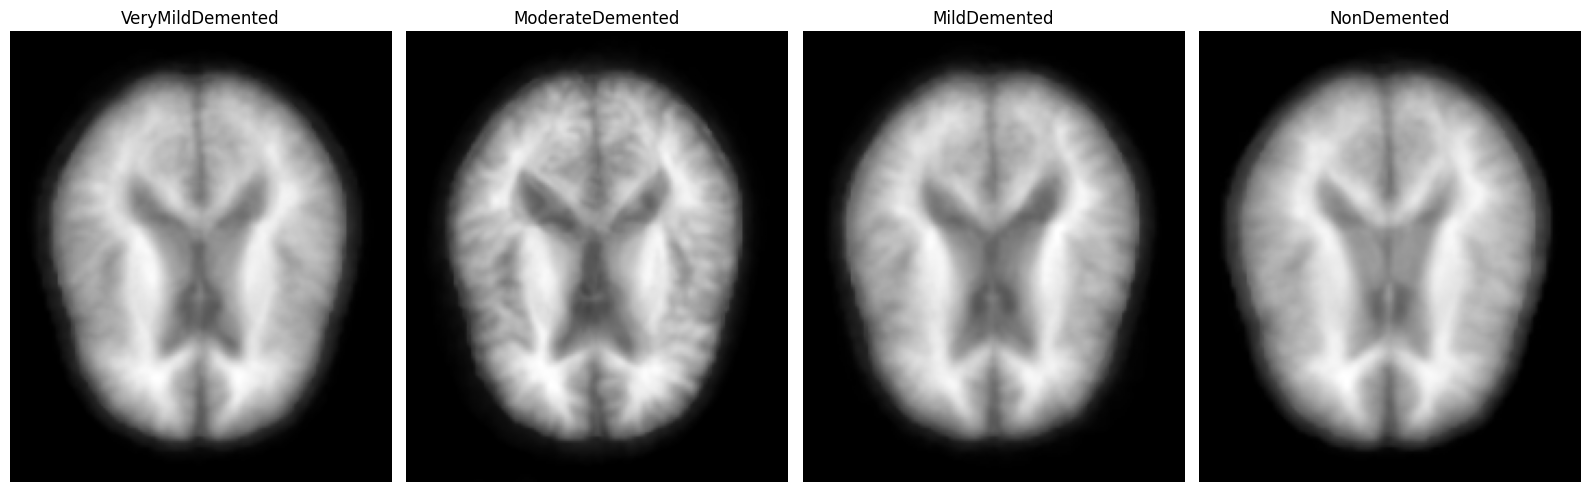

In [19]:
# mean MRI image visualization for each class

plt.figure(figsize=(16,5))

for i, cls in enumerate(classes):

    class_path = os.path.join(dataset_path, cls)

    images = os.listdir(class_path)[:100]

    mean_image = np.zeros((208,176))

    for img_name in images:

        img_path = os.path.join(class_path, img_name)

        img = cv2.imread(
            img_path,
            cv2.IMREAD_GRAYSCALE
        )

        img = cv2.resize(img, (176,208))

        mean_image += img

    mean_image = mean_image / len(images)

    plt.subplot(1,4,i+1)

    plt.imshow(mean_image, cmap='gray')

    plt.title(cls)

    plt.axis('off')

plt.tight_layout()

plt.show()

In [20]:
# dataset summary statistics

total_images = sum(class_counts.values())

print("Dataset Summary\n")

print("Total Classes :", len(classes))

print("Total Images  :", total_images)

print("\nClass-wise Statistics:\n")

for cls, count in class_counts.items():

    percentage = (count / total_images) * 100

    print(f"{cls} : {count} images ({percentage:.2f}%)")

Dataset Summary

Total Classes : 4
Total Images  : 33984

Class-wise Statistics:

VeryMildDemented : 8960 images (26.37%)
ModerateDemented : 6464 images (19.02%)
MildDemented : 8960 images (26.37%)
NonDemented : 9600 images (28.25%)
